<a href="https://colab.research.google.com/github/geethika108/DLAC/blob/main/DL_skill2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install ultralytics fastapi uvicorn python-multipart httpx pillow

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 7.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [ultralytics]


In [ ]:
import torch

if torch.cuda.is_available():
    device = "cuda:0"
    print("GPU is available!")
    print("GPU Name:", torch.cuda.get_device_name(0))
else:
    device = "cpu"
    print("GPU is not available. Using CPU.")

print("Selected device:", device)


GPU is available!
GPU Name: Tesla T4
Selected device: cuda:0


In [ ]:
from ultralytics import YOLO

# Load YOLO11 nano model
model = YOLO("yolo11n.pt")

print("YOLO model loaded successfully!")
print("Using device:", device)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
YOLO model loaded successfully!
Using device: cuda:0


In [ ]:
from fastapi import FastAPI, UploadFile, File, HTTPException
from PIL import Image
import io

# Create FastAPI application
app = FastAPI(title="VisionPort Object Detection API")

print("VisionPort API created successfully!")

VisionPort API created successfully!


In [ ]:
@app.get("/")
def home():
    return {
        "message": "Welcome to VisionPort",
        "status": "API is running"
    }

In [ ]:
from collections import Counter

@app.post("/detect")
async def detect_objects(file: UploadFile = File(...)):

    # Check whether uploaded file is an image
    if not file.content_type or not file.content_type.startswith("image/"):
        raise HTTPException(
            status_code=400,
            detail="Please upload a valid image"
        )

    try:
        # Read uploaded image
        image_bytes = await file.read()

        # Convert uploaded bytes into an image
        image = Image.open(
            io.BytesIO(image_bytes)
        ).convert("RGB")

        # Perform object detection
        results = model.predict(
            source=image,
            conf=0.25,
            device=device
        )

        result = results[0]

        detections = []

        # Extract detected objects
        for box in result.boxes:

            class_id = int(box.cls[0])

            object_name = result.names[class_id]

            confidence = float(box.conf[0])

            coordinates = box.xyxy[0].tolist()

            detections.append({
                "object": object_name,
                "confidence": round(confidence * 100, 2),
                "bounding_box": [
                    round(value, 2) for value in coordinates
                ]
            })

        # Count each object category
        object_counts = dict(
            Counter(item["object"] for item in detections)
        )

        # Return detection results
        return {
            "filename": file.filename,
            "total_objects": len(detections),
            "object_counts": object_counts,
            "detections": detections
        }

    except HTTPException:
        raise

    except Exception as e:
        raise HTTPException(
            status_code=400,
            detail=f"Unable to process image: {str(e)}"
        )

In [ ]:
from fastapi.testclient import TestClient

# Create test client
client = TestClient(app)

# Test home endpoint
response = client.get("/")

print("Status Code:", response.status_code)
print("Response:", response.json())

Status Code: 200
Response: {'message': 'Welcome to VisionPort', 'status': 'API is running'}


In [9]:
from google.colab import files

# Upload image
uploaded = files.upload()

# Get uploaded filename
filename = next(iter(uploaded.keys()))

# Send image to FastAPI detection endpoint
with open(filename, "rb") as image_file:

    response = client.post(
        "/detect",
        files={
            "file": (
                filename,
                image_file,
                "image/jpeg"
            )
        }
    )

# Display API response
print("Status Code:", response.status_code)

data = response.json()

print("\nVISIONPORT DETECTION RESULTS")
print("--------------------------------")

print("Filename:", data.get("filename"))
print("Total Objects:", data.get("total_objects"))

print("\nObject-wise Count:")

for name, count in data.get("object_counts", {}).items():
    print(name, ":", count)

print("\nIndividual Detections:")

for detection in data.get("detections", []):
    print(detection)

Saving poster-people-street-crosswalk_961875-367143.avif to poster-people-street-crosswalk_961875-367143.avif

0: 448x640 8 persons, 3 cars, 2 traffic lights, 7.9ms
Speed: 76.6ms preprocess, 7.9ms inference, 20.4ms postprocess per image at shape (1, 3, 448, 640)
Status Code: 200

VISIONPORT DETECTION RESULTS
--------------------------------
Filename: poster-people-street-crosswalk_961875-367143.avif
Total Objects: 13

Object-wise Count:
car : 3
person : 8
traffic light : 2

Individual Detections:
{'object': 'car', 'confidence': 91.28, 'bounding_box': [1658.15, 823.33, 1998.49, 1102.5]}
{'object': 'car', 'confidence': 91.12, 'bounding_box': [1.87, 828.89, 693.86, 1100.53]}
{'object': 'person', 'confidence': 87.4, 'bounding_box': [888.92, 792.94, 1010.61, 1210.64]}
{'object': 'person', 'confidence': 85.49, 'bounding_box': [1483.29, 772.9, 1606.12, 1182.18]}
{'object': 'person', 'confidence': 85.02, 'bounding_box': [1019.23, 800.08, 1140.99, 1207.23]}
{'object': 'person', 'confidence': 84


image 1/1 /content/poster-people-street-crosswalk_961875-367143.avif: 448x640 8 persons, 3 cars, 2 traffic lights, 129.4ms
Speed: 15.9ms preprocess, 129.4ms inference, 14.8ms postprocess per image at shape (1, 3, 448, 640)


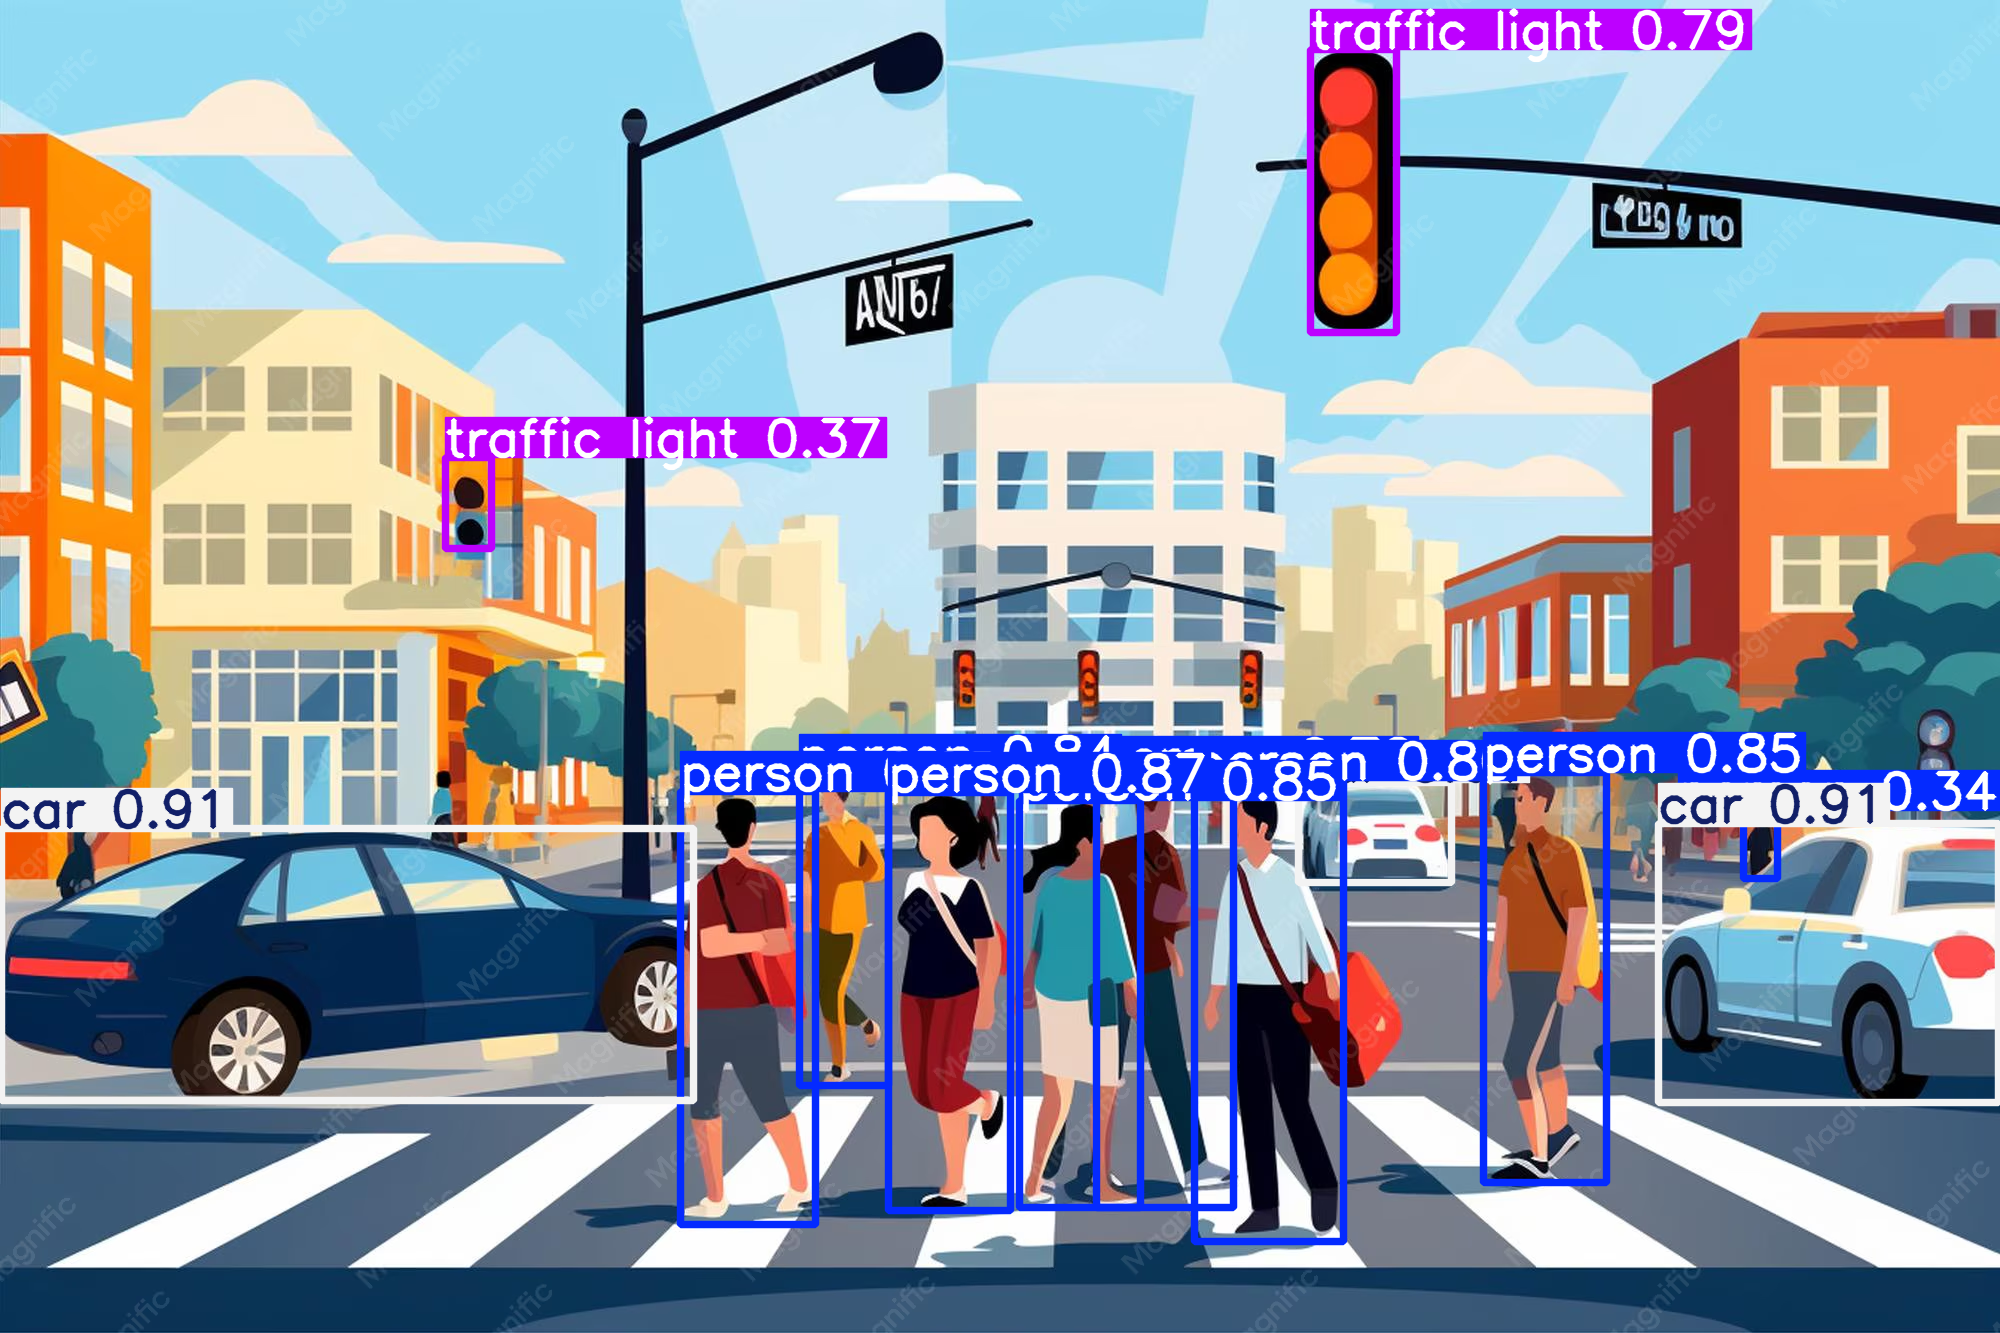

In [11]:
from IPython.display import display

# Run YOLO on the uploaded image
results = model.predict(
    source=filename,
    conf=0.25,
    device=device
)

# Get image with bounding boxes
annotated_image = results[0].plot()

# Convert BGR to RGB and display
display(
    Image.fromarray(annotated_image[:, :, ::-1])
)

In [12]:
print("========== VISIONPORT SUMMARY ==========")

print("Image:", filename)

print("Total Objects Detected:", data["total_objects"])

print("\nDetected Object Categories:")

for name, count in data["object_counts"].items():
    print(f"{name}: {count}")

print("\nDetection Details:")

for i, item in enumerate(data["detections"], start=1):

    print(f"\nObject {i}")
    print("Name:", item["object"])
    print("Confidence:", item["confidence"], "%")
    print("Bounding Box:", item["bounding_box"])

print("\n========== DETECTION COMPLETED ==========")

========== VISIONPORT SUMMARY ==========
Image: poster-people-street-crosswalk_961875-367143.avif
Total Objects Detected: 13

Detected Object Categories:
car: 3
person: 8
traffic light: 2

Detection Details:

Object 1
Name: car
Confidence: 91.28 %
Bounding Box: [1658.15, 823.33, 1998.49, 1102.5]

Object 2
Name: car
Confidence: 91.12 %
Bounding Box: [1.87, 828.89, 693.86, 1100.53]

Object 3
Name: person
Confidence: 87.4 %
Bounding Box: [888.92, 792.94, 1010.61, 1210.64]

Object 4
Name: person
Confidence: 85.49 %
Bounding Box: [1483.29, 772.9, 1606.12, 1182.18]

Object 5
Name: person
Confidence: 85.02 %
Bounding Box: [1019.23, 800.08, 1140.99, 1207.23]

Object 6
Name: person
Confidence: 84.56 %
Bounding Box: [680.04, 791.69, 815.02, 1224.55]

Object 7
Name: person
Confidence: 84.4 %
Bounding Box: [799.18, 774.52, 888.43, 1085.94]

Object 8
Name: person
Confidence: 80.48 %
Bounding Box: [1194.67, 780.37, 1343.85, 1241.64]

Object 9
Name: traffic light
Confidence: 79.49 %
Bounding Box: [13